=== HASIL EVALUASI MODEL DECISION TREE ===
Akurasi Model : 67.74%

Classification Report:
              precision    recall  f1-score   support

   Sehat (0)       0.64      0.64      0.64        14
   Sakit (1)       0.71      0.71      0.71        17

    accuracy                           0.68        31
   macro avg       0.67      0.67      0.67        31
weighted avg       0.68      0.68      0.68        31



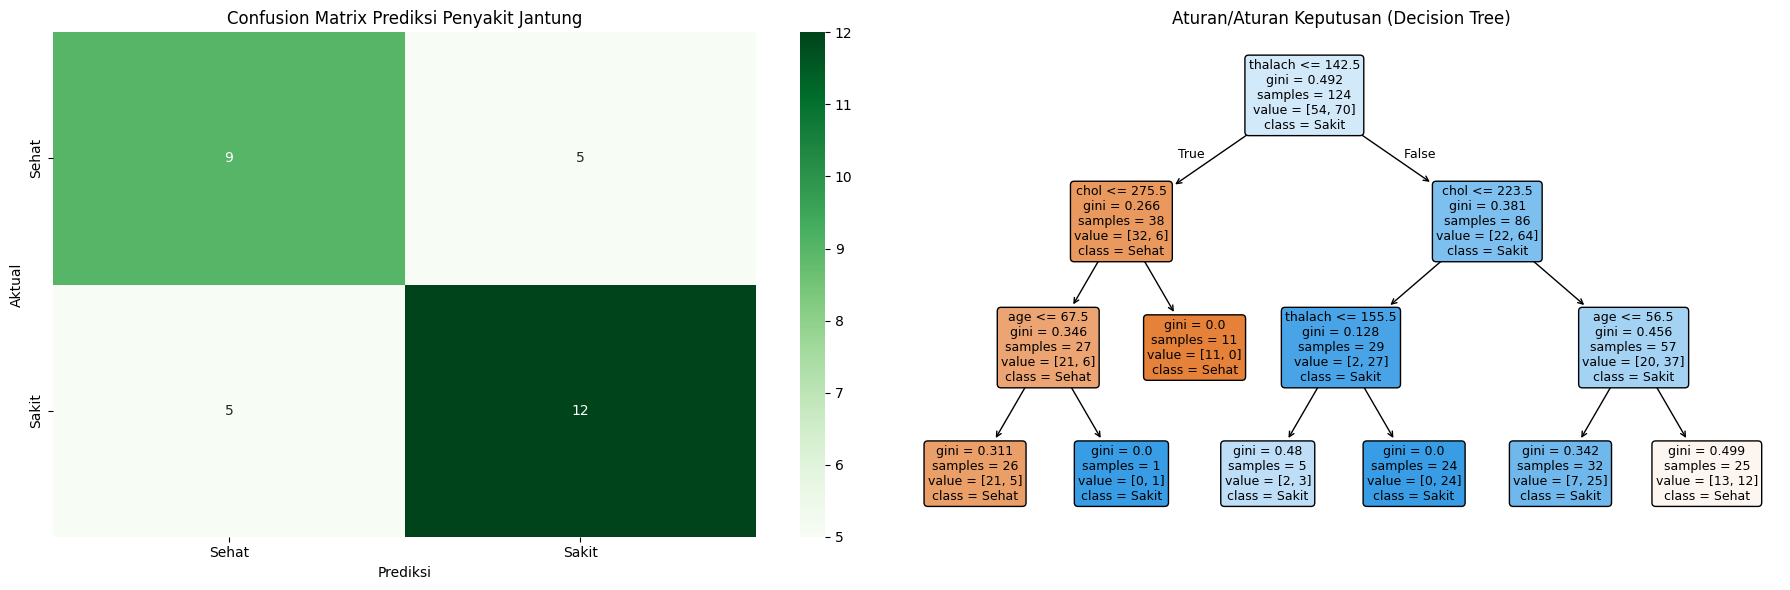

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. LOAD DATASET
url = "https://raw.githubusercontent.com/pmarcelino/datasets/master/heart.csv"
df = pd.read_csv(url)

# 2. PEMBERSIHAN DATA & PREPROCESSING
# A. Cek missing values (jika ada, diisi atau dihapus)
df = df.dropna()

# B. Memisahkan Fitur (X) dan Target (y)
# Target 'target': 1 (Penyakit Jantung), 0 (Sehat)
X = df.drop(columns=['target'])
y = df['target']

# C. Train-Test Split (80:20)
# Catatan: Decision Tree TIDAK membutuhkan StandardScaler karena tidak sensitif terhadap skala data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. TRAINING MODEL
# Gunakan max_depth agar pohon tidak terlalu rimbun/overfitting dan gampang dibaca
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

# 4. PREDIKSI & EVALUASI
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print("=== HASIL EVALUASI MODEL DECISION TREE ===")
print(f"Akurasi Model : {acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Sehat (0)', 'Sakit (1)']))

# 5. VISUALISASI HASIL
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Visualisasi 1: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[0],
    xticklabels=['Sehat', 'Sakit'],
    yticklabels=['Sehat', 'Sakit']
)
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Aktual")
axes[0].set_title("Confusion Matrix Prediksi Penyakit Jantung")

# Visualisasi 2: Pohon Keputusan (Decision Tree)
plot_tree(
    model,
    feature_names=X.columns,
    class_names=['Sehat', 'Sakit'],
    filled=True,
    rounded=True,
    ax=axes[1],
    fontsize=9
)
axes[1].set_title("Aturan/Aturan Keputusan (Decision Tree)")

plt.tight_layout()
plt.show()